## Figure 1: Forecast and Method

**Inputs:** `../data/figures/v261102_fig1{a,b,c}.zarr`, written by `d01_prep_data_p01.ipynb`.

**Forecast period:** Oct–Mar (`FC_MONTHS`).

- **(a) Forecast anomaly map.** Gridded Ensemble-mean 2 m temperature anomaly averaged over Oct–Mar (°C), land only. Hatching marks grid cells where fewer than 80% of ensemble members agree on the sign of the anomaly.
  *Sources:* parsed seasonal forecast (`v20261006_parsed_forecast.zarr`, daily, per ensemble member), relative to parsed hindcast climatology (`v20261006_parsed_hindcast.zarr`, daily ensemble mean).
- **(b) Method diagram.** Single region (Kgalagadi, Botswana, `BWA.3`), one month (January) and one age group (65+). 3 panel elements: histograms of daily temperature for the forecast members and for ERA5; the hot-only response curve, with its samples (gamma) and the gamma sample mean MMT; and the cumulative mortality effect (e.g. cdf), with a 5–95% range across samples.
  *Sources:* Gridded 6-month Forecast and ERA5 for 1996–2025 (`POREALLAS_ERA5_URI`), both aggregated to impact regions. Response curves in `POREALLAS_EFFECTS_URI` (`/fixed_beta`, `beta_hotonly`).
- **(c) Response-curve slope map.** The mortality rate slope d(β)/d(T) for age_cohort ages 65+, evaluated at each region's Oct–Mar ensemble-mean forecast temperature and averaged across response-curve gamma samples (rate/°C).
  *Sources:* Full response curve in `POREALLAS_EFFECTS_URI` (`/fixed_beta`, `beta`), IR-aggregated forecast

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os
from datetime import UTC, datetime

import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from dotenv import find_dotenv, load_dotenv

from utils import analysis_utils, isku_utils, plotting_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [2]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

In [3]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    age_weight=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [4]:
FIG1A_PATH = "../data/figures/v261103_fig1a.zarr"
FIG1B_PATH = "../data/figures/v261103_fig1b.zarr"
FIG1C_PATH = "../data/figures/v261103_fig1c.zarr"

In [5]:
def _flat(da):
    # Flatten and check xarray
    v = np.asarray(da).ravel()
    return v[np.isfinite(v)]


def load_panel_a(path):
    ds = xr.open_zarr(path, consolidated=True).load()
    return ds["ens_mean"], ds["agreement"], ds.attrs


def load_panel_b(path, pad=3):
    ds = xr.open_zarr(path, consolidated=True).load()
    fc, era5 = ds["fc_tas"], ds["era5_tas"]
    vals = np.concatenate([_flat(fc), _flat(era5)])
    clim = {
        "forecast": fc,
        "era5": era5,
        "n_members": fc.sizes["number"],
        "n_years": np.unique(era5["era5_time"].dt.year).size,
        "xlim": (vals.min() - pad, vals.max() + pad),
    }
    beta = {
        "samples": ds["beta"].values,
        "tas_bin": ds["tas_bin"].values,
        "mmt": ds["mmt"].item(),
    }
    return clim, beta, ds.attrs


def load_panel_c(path, polygons):
    ds = xr.open_zarr(path, consolidated=True).load()
    gdf = analysis_utils.xarray_to_gpd(ds["beta_slope_at_forecast"], polygons)
    return gdf.to_crs(ccrs.Robinson().proj4_init), ds.attrs

In [6]:
## Climate Data Processing ##
def bin_edges(tas_bin):
    # Standardize bin edges for discrete plotting
    tas_bin = np.asarray(tas_bin)
    return np.append(tas_bin, tas_bin[-1] + np.diff(tas_bin)[-1])


def plot_climate_hist(ax, clim, edges, colors):
    # Plot climate histograms
    # Weighted for "days per month" across ERA5 years and forecast members
    for key, n, label in [
        ("era5", clim["n_years"], "ERA5"),
        ("forecast", clim["n_members"], "Forecast"),
    ]:
        v = _flat(clim[key])
        ax.hist(
            v,
            bins=edges,
            weights=np.full(v.size, 1 / n),
            alpha=0.5,
            color=colors[key],
            label=label,
        )
    ax.set_xlim(*clim["xlim"])


## Response Curve ##
def plot_response(ax, beta, color, ylim=(0, 10)):
    # Plot response curve and samples
    x, s = beta["tas_bin"], beta["samples"]
    ax.step(x, s.T, where="pre", color=color, lw=0.5, alpha=0.15)
    ax.step(
        x,
        np.nanmean(s, axis=0),
        where="pre",
        color=color,
        lw=2,
        label="Response curve",
    )
    ax.axvline(beta["mmt"], color=color, lw=1, label="MMT")
    ax.set_ylim(*ylim)
    ax.spines["top"].set_visible(False)

In [7]:
def plot_cdf(ax, cdf, colors):
    # Add CDF for forecast and era5 to plot
    for key, label in [("forecast", "Forecast"), ("era5", "ERA5")]:
        c = cdf[key]
        ax.fill_between(
            cdf["x"], c["lo"], c["hi"], step="pre", color=colors[key], alpha=0.25, lw=0
        )
        ax.step(cdf["x"], c["mean"], where="pre", color=colors[key], label=label)
    ax.set_ylim(0, cdf["max"] * 1.1)

In [8]:
## CDF ##
def compute_cdf(clim, beta, q=(5, 95)):
    # CDF and Uncertainty Range
    edges = bin_edges(beta["tas_bin"])
    out = {"x": beta["tas_bin"]}
    for key, n in [("era5", clim["n_years"]), ("forecast", clim["n_members"])]:
        counts, _ = np.histogram(_flat(clim[key]), bins=edges)
        # Cumulative mortality rate = response curve * histogram / num. samples
        cdf = np.cumsum(beta["samples"] * counts / n, axis=1)  # (sample, tas_bin)
        out[key] = {
            "mean": np.nanmean(cdf, axis=0),
            "lo": np.nanpercentile(cdf, q[0], axis=0),
            "hi": np.nanpercentile(cdf, q[1], axis=0),
        }
    # Log for ylim
    out["max"] = max(out["era5"]["hi"].max(), out["forecast"]["hi"].max())
    return out


def plot_region_panel(
    fig,
    spec,
    clim,
    beta,
    colors,
    title=None,
    show_left_labels=True,
    show_right_labels=True,
    q=(5, 95),
    response_ylim=(0, 10),
):
    cdf = compute_cdf(clim, beta, q=q)
    inner = spec.subgridspec(2, 1, height_ratios=[3, 1], hspace=0.08)
    ax_hist = fig.add_subplot(inner[0])
    ax_cdf = fig.add_subplot(inner[1], sharex=ax_hist)
    ax_resp = ax_hist.twinx()
    ax_hist.tick_params(labelbottom=False)

    plot_climate_hist(ax_hist, clim, bin_edges(beta["tas_bin"]), colors)
    plot_response(ax_resp, beta, colors["response"], ylim=response_ylim)
    plot_cdf(ax_cdf, cdf, colors)

    ax_cdf.set_xlabel("Tas [°C]")
    if show_left_labels:
        ax_hist.set_ylabel("Days per Month")
        ax_cdf.set_ylabel("Cum. effect\n[Deaths/100k]")
    if show_right_labels:
        ax_resp.set_ylabel("Daily Response 65+\n[deaths/100k]")
    if title:
        ax_hist.set_title(title)

    return ax_hist, ax_resp, ax_cdf

# Load Data
From d01

In [9]:
ens_mean, mask, attrs_a = load_panel_a(FIG1A_PATH)
clim_b, beta_b, attrs_b = load_panel_b(FIG1B_PATH)
gdf_rob, attrs_c = load_panel_c(FIG1C_PATH, config.polygons)

## Build Figure

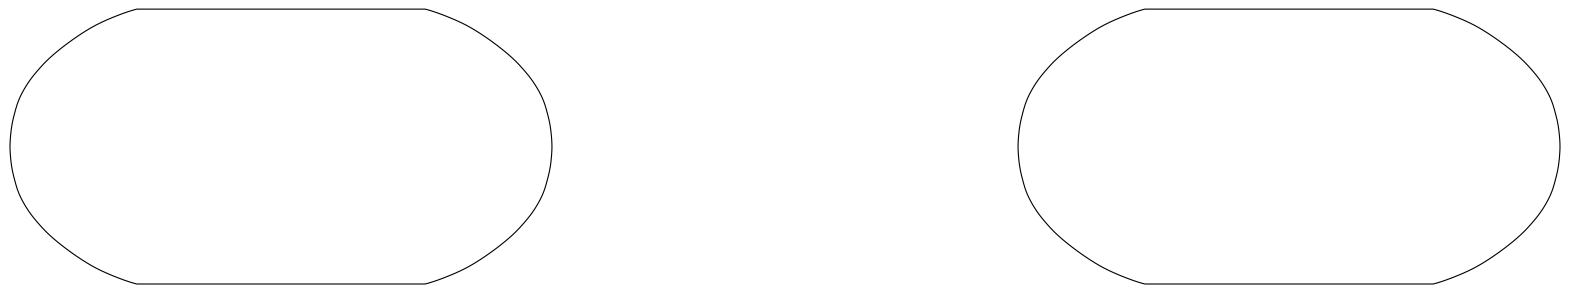

In [10]:
### Set Colors ###
COLORS = {"era5": "#999999", "forecast": "#ffbb6f", "response": "#5e4c5f"}

fig = plt.figure(figsize=(20, 5.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.6, 1], wspace=0.15)

ax_map1 = fig.add_subplot(gs[0], projection=ccrs.Robinson())  # Forecast
ax_map3 = fig.add_subplot(gs[2], projection=ccrs.Robinson())  # Slope

In [11]:
### Plot Forecast Mean ###
step = 0.5
vmax = np.ceil(float(abs(ens_mean).quantile(0.98)) / step) * step
levels = np.arange(-vmax, vmax + step, step)
# Plot ensemble mean
mesh = ens_mean.plot.pcolormesh(
    ax=ax_map1,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=levels,
    extend="both",
    add_colorbar=False,
)

ax_map1.coastlines(linewidth=0.6, color="k")

ax_map1.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
ax_map1.spines["geo"].set_visible(False)

fig.colorbar(
    mesh,
    ax=ax_map1,
    orientation="horizontal",
    shrink=0.6,
    pad=0.05,
    label="Temperature anomaly (°C)",
)
# Add Hatching: Sign greement across ensemble members
plotting_utils.add_polygons(ax_map1, mask, transform=ccrs.PlateCarree())

In [12]:
# Slope Map
cmap = plt.get_cmap("coolwarm")
levels = np.linspace(-1, 1, 9)
norm = mcolors.BoundaryNorm(levels, cmap.N, extend="both")

gdf_rob.plot(
    ax=ax_map3,
    column="beta_slope_at_forecast",
    cmap=cmap,
    norm=norm,
    linewidth=0,
    aspect=None,
    missing_kwds={"color": "lightgray"},
)
ax_map3.coastlines(linewidth=0.6, color="k")
ax_map3.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
ax_map3.spines["geo"].set_visible(False)
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_map3,
    orientation="horizontal",
    shrink=0.7,
    aspect=30,
    pad=0.03,
    label=f"Slope @ Avg. Forecast [{attrs_c['units']}]",
)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/shapely/constructive.py:829: RuntimeWarning: invalid value encountered in normalize
  return lib.normalize(geometry, **kwargs)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/shapely/constructive.py:829: RuntimeWarning: invalid value encountered in normalize
  return lib.normalize(geometry, **kwargs)


In [13]:
# Plot Region Panel
ax_hist, ax_resp, _ = plot_region_panel(
    fig,
    gs[1],
    clim_b,
    beta_b,
    COLORS,
    title=attrs_b["region_title"],
    show_left_labels=True,
    show_right_labels=True,
)

h1, l1 = ax_hist.get_legend_handles_labels()
h2, l2 = ax_resp.get_legend_handles_labels()
ax_resp.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, frameon=False)

# ---- Panel labels ----
for label, a in zip("ac", [ax_map1, ax_map3]):
    a.text(
        0.0,
        1.03,
        f"({label})",
        transform=a.transAxes,
        fontsize=12,
        fontweight="bold",
        va="bottom",
        ha="left",
    )
ax_hist.text(
    -0.12,
    1.03,
    "(b)",
    transform=ax_hist.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom",
    ha="left",
)

Text(-0.12, 1.03, '(b)')

In [14]:
fig.savefig(f"{config.version}_method_diagram_map.png", dpi=600, bbox_inches="tight")

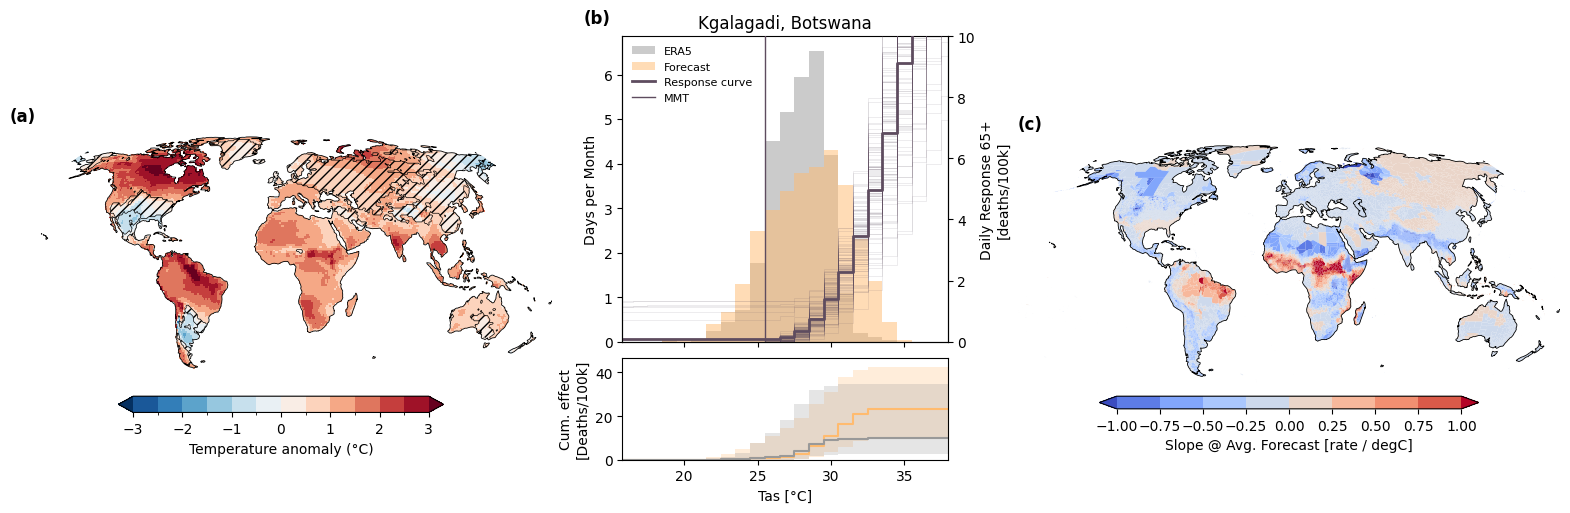

In [15]:
fig